# 02 · Análisis exploratorio

Precios mensuales de tomate, papa Loman y chile pimiento · La Terminal.

## 1. Carga y variables de análisis

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Ubicamos el CSV preparado y la carpeta donde guardaremos los resultados.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = Path('/content/drive/MyDrive/MAGA_Analisis_Fase2')
except ImportError:
    RAIZ = Path(os.environ.get('MAGA_PROJECT_DIR', Path.cwd() / 'MAGA_Analisis_Fase2'))

ENTRADA = RAIZ / 'data/prepared/maga_precios_mensuales_la_terminal_1998_2026.csv'
SALIDA = RAIZ / 'outputs/02_analisis_exploratorio'
SALIDA.mkdir(parents=True, exist_ok=True)
# Usamos nombres cortos para identificar cada producto en las gráficas.
NOMBRES = {
    'Tomate de cocina, grande, de primera': 'Tomate',
    'Papa Loman, lavada, grande, de primera': 'Papa Loman',
    'Chile Pimiento, grande, de primera': 'Chile pimiento',
}
ORDEN = list(NOMBRES.values())
COLORES = {'Tomate': '#BB7979', 'Papa Loman': '#6A996A', 'Chile pimiento': '#378A94'}
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

if not ENTRADA.is_file():
    raise FileNotFoundError('Ejecuta primero el Notebook 01: falta el CSV preparado.')
datos = pd.read_csv(ENTRADA, encoding='utf-8-sig', parse_dates=['Fecha'])
if len(datos) != 1029 or set(datos['Producto']) != set(NOMBRES):
    raise ValueError('La entrada no corresponde a las tres series del Notebook 01.')
if datos['Precio'].isna().any() or (datos['Precio'] <= 0).any() or datos.duplicated(['Producto', 'Fecha']).any():
    raise ValueError('La entrada contiene precios inválidos o fechas duplicadas.')

# Calculamos los cambios mensuales y una media móvil para analizar las series.
datos['Producto_corto'] = datos['Producto'].map(NOMBRES)
series = datos.sort_values(['Producto_corto', 'Fecha']).reset_index(drop=True)
g = series.groupby('Producto_corto')['Precio']
series['Cambio_pct'] = g.pct_change(fill_method=None) * 100
series['Cambio_abs_pct'] = series['Cambio_pct'].abs()
series['Media_movil_12'] = g.transform(lambda x: x.rolling(12, min_periods=12).mean())
assert series.groupby('Producto_corto')['Cambio_pct'].count().eq(342).all()

fmt_q = FuncFormatter(lambda x, pos: f'Q{x:,.0f}')
def grafica(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def tabla(df, nombre):
    df.to_csv(SALIDA / nombre, index=False, encoding='utf-8-sig')

Mounted at /content/drive


## 2. Estadística descriptiva y evolución histórica

,Producto_corto,Meses,Media,Mediana,Minimo,Maximo,Desviacion,Inicial,Final,Variacion_periodo_pct
0,Tomate,343,111.91,103.75,20.07,374.55,47.03,135.00,120.22,-10.95
1,Papa Loman,343,193.70,180.00,47.14,621.25,92.24,129.17,401.30,210.68
2,Chile pimiento,343,87.73,82.08,23.75,268.98,34.43,70.00,133.04,90.06


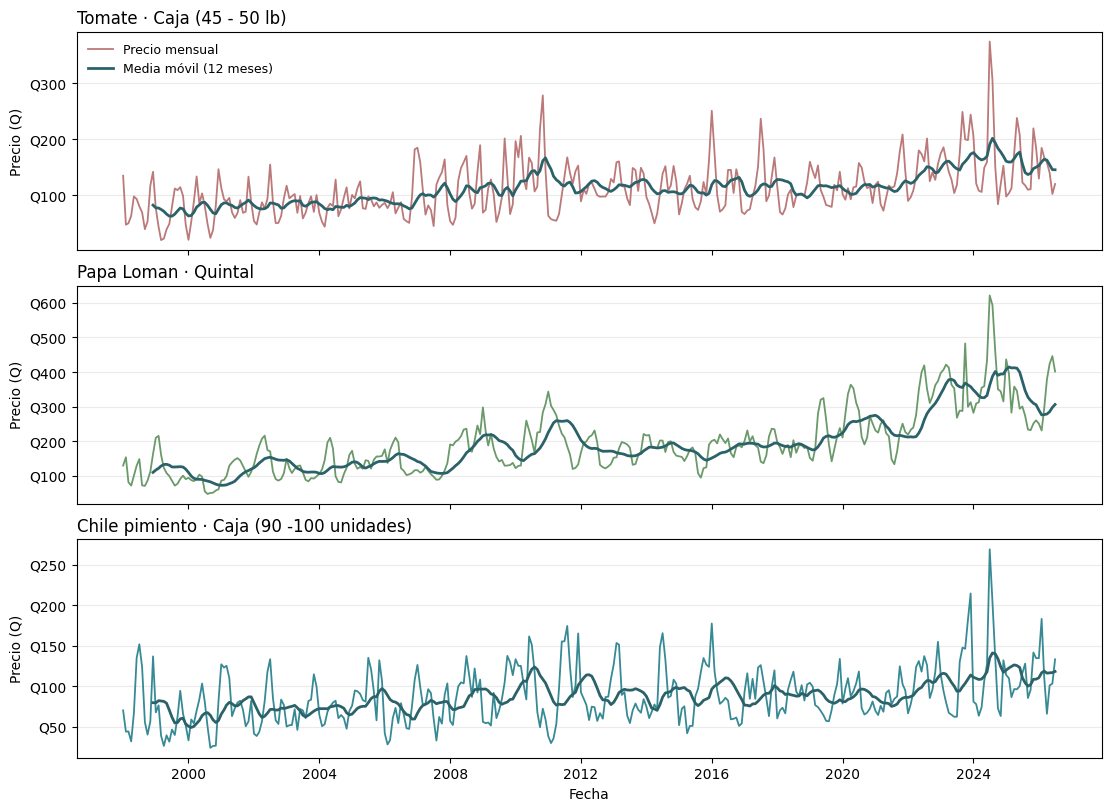

In [2]:
# Obtenemos las estadísticas principales de los precios.
resumen = (series.groupby('Producto_corto')['Precio']
           .agg(Meses='size', Media='mean', Mediana='median', Minimo='min', Maximo='max', Desviacion='std',
                Inicial='first', Final='last').reindex(ORDEN).reset_index())
resumen['Variacion_periodo_pct'] = (resumen['Final'] / resumen['Inicial'] - 1) * 100
display(resumen.round(2))
tabla(resumen, '02_estadisticas.csv')

# Mostramos la evolución de cada producto con su media móvil de 12 meses.
fig, ejes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout='constrained')
for ax, producto in zip(ejes, ORDEN):
    d = series.loc[series['Producto_corto'].eq(producto)]
    ax.plot(d['Fecha'], d['Precio'], color=COLORES[producto], lw=1.3, label='Precio mensual')
    ax.plot(d['Fecha'], d['Media_movil_12'], color='#2B6269', lw=2, label='Media móvil (12 meses)')
    ax.set_title(f'{producto} · {d["Medida"].iloc[0]}', loc='left')
    ax.yaxis.set_major_formatter(fmt_q)
    ax.set_ylabel('Precio (Q)')
    ax.grid(axis='y', alpha=.25)
ejes[0].legend(frameon=False, fontsize=9)
ejes[-1].set_xlabel('Fecha')
grafica(fig, '02_evolucion.png')

## 3. Variabilidad mensual

,Producto_corto,Cambios,Cambio_medio_pct,Desviacion_pct,Cambio_absoluto_medio_pct,Frecuencia_20pct
0,Tomate,342,5.89,36.71,27.53,53.51
1,Papa Loman,342,1.87,17.57,13.32,21.93
2,Chile pimiento,342,5.47,35.33,25.59,48.25


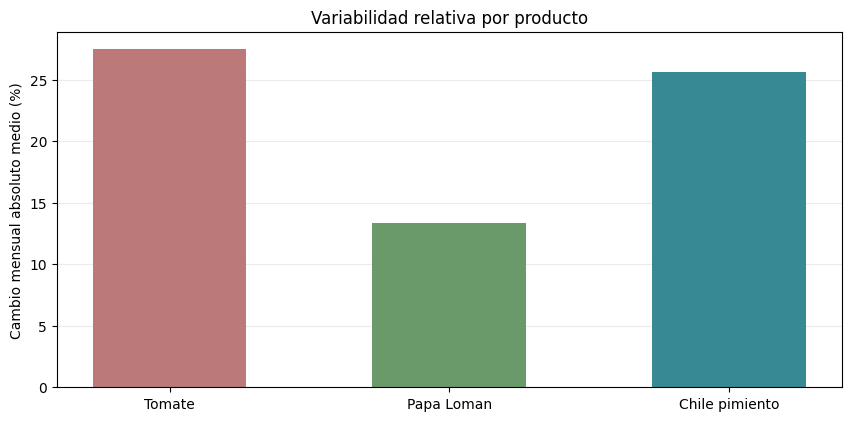

In [3]:
# Medimos qué tanto cambian los precios y con qué frecuencia.
variabilidad = (series.groupby('Producto_corto')
    .agg(Cambios=('Cambio_pct', 'count'), Cambio_medio_pct=('Cambio_pct', 'mean'),
         Desviacion_pct=('Cambio_pct', 'std'), Cambio_absoluto_medio_pct=('Cambio_abs_pct', 'mean'),
         Frecuencia_20pct=('Cambio_abs_pct', lambda s: 100 * (s.dropna() >= 20).mean()))
    .reindex(ORDEN).reset_index())
display(variabilidad.round(2))
tabla(variabilidad, '02_variabilidad.csv')

fig, ax = plt.subplots(figsize=(8.4, 4.1), layout='constrained')
ax.bar(variabilidad['Producto_corto'], variabilidad['Cambio_absoluto_medio_pct'],
       color=[COLORES[p] for p in ORDEN], width=.55)
ax.set_ylabel('Cambio mensual absoluto medio (%)')
ax.set_title('Variabilidad relativa por producto')
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
grafica(fig, '02_variabilidad.png')

## 4. Patrones mensuales

Mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Producto_corto,,,,,,,,,,,,
Tomate,-29.1,-10.2,1.0,11.3,9.4,1.4,12.3,-2.1,-6.7,7.8,17.7,21.5
Papa Loman,7.1,0.6,1.2,10.9,1.7,-3.9,-7.1,-16.5,-3.6,8.4,6.5,5.2
Chile pimiento,-32.4,-4.1,0.5,-3.5,9.4,4.1,9.8,-15.3,-12.4,2.2,13.5,17.6


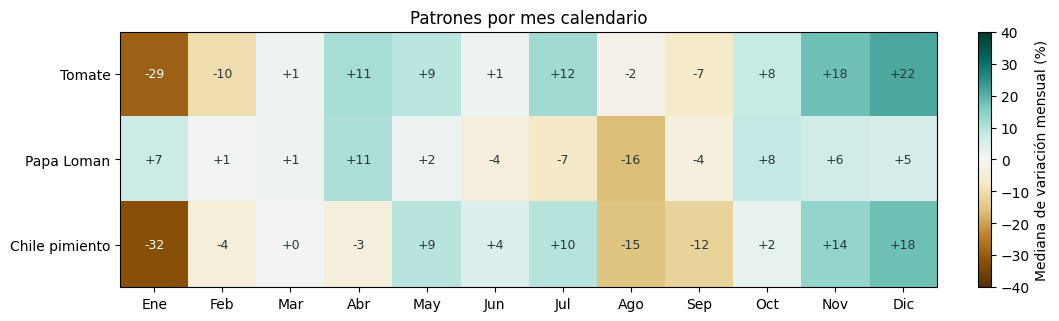

In [4]:
# Agrupamos las variaciones por mes para buscar patrones recurrentes.
estacionalidad = (series.groupby(['Producto_corto', 'Mes'])['Cambio_pct']
                .agg(Meses='count', Mediana_pct='median', Media_pct='mean').reset_index())
matriz = estacionalidad.pivot(index='Producto_corto', columns='Mes', values='Mediana_pct').loc[ORDEN]
display(matriz.rename(columns=dict(enumerate(MESES, 1))).round(1))
tabla(estacionalidad, '02_estacionalidad.csv')

# La matriz de calor facilita comparar esos cambios entre productos.
limite = max(20, float(np.ceil(np.abs(matriz.to_numpy()).max() / 10) * 10))
fig, ax = plt.subplots(figsize=(10.5, 3.1), layout='constrained')
im = ax.imshow(matriz.to_numpy(), cmap='BrBG', vmin=-limite, vmax=limite, aspect='auto')
ax.set_xticks(range(12), MESES)
ax.set_yticks(range(3), ORDEN)
for i in range(3):
    for j in range(12):
        v = matriz.iloc[i, j]
        ax.text(j, i, f'{v:+.0f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > limite * .65 else '#26383C')
fig.colorbar(im, ax=ax, label='Mediana de variación mensual (%)')
ax.set_title('Patrones por mes calendario')
grafica(fig, '02_patrones_mensuales.png')

## 5. Fluctuaciones relevantes

,Producto_corto,Fecha,Precio,Cambio_pct,Medida
35,Chile pimiento,2000-12-01,81.11,208.40,Caja (90 -100 unidades)
11,Chile pimiento,1998-12-01,136.67,141.72,Caja (90 -100 unidades)
94,Chile pimiento,2005-11-01,131.92,128.67,Caja (90 -100 unidades)
318,Chile pimiento,2024-07-01,268.98,111.38,Caja (90 -100 unidades)
323,Chile pimiento,2024-12-01,131.88,109.33,Caja (90 -100 unidades)
652,Papa Loman,2023-10-01,482.50,68.12,Quintal
598,Papa Loman,2019-04-01,279.12,56.93,Quintal
490,Papa Loman,2010-04-01,199.17,54.12,Quintal
558,Papa Loman,2015-12-01,190.00,53.02,Quintal
350,Papa Loman,1998-08-01,71.92,-51.36,Quintal


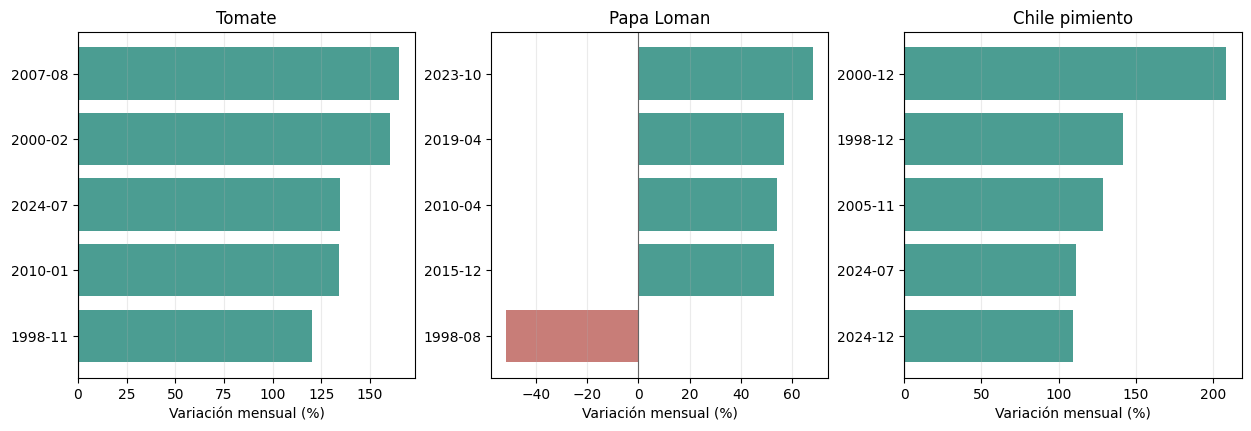

In [5]:
# Identificamos los cinco mayores cambios mensuales de cada producto.
extremos = (series.dropna(subset=['Cambio_pct'])
            .sort_values('Cambio_abs_pct', ascending=False)
            .groupby('Producto_corto', group_keys=False).head(5)
            .sort_values(['Producto_corto', 'Cambio_abs_pct'], ascending=[True, False]))
principales = extremos[['Producto_corto', 'Fecha', 'Precio', 'Cambio_pct', 'Medida']].copy()
display(principales.round(2))
tabla(principales, '02_fluctuaciones.csv')

fig, ejes = plt.subplots(1, 3, figsize=(12.4, 4.2), layout='constrained')
for ax, producto in zip(ejes, ORDEN):
    d = extremos.loc[extremos['Producto_corto'].eq(producto)].sort_values('Cambio_pct')
    ax.barh(d['Fecha'].dt.strftime('%Y-%m'), d['Cambio_pct'],
            color=np.where(d['Cambio_pct'] >= 0, '#4B9D92', '#C87D78'))
    ax.axvline(0, color='#666', lw=.8)
    ax.set_title(producto)
    ax.set_xlabel('Variación mensual (%)')
    ax.grid(axis='x', alpha=.25)
grafica(fig, '02_fluctuaciones.png')

## 6. Relaciones entre productos

Producto_corto,Tomate,Papa Loman,Chile pimiento
Producto_corto,,,
Tomate,1.000,0.036,0.459
Papa Loman,0.036,1.000,0.112
Chile pimiento,0.459,0.112,1.000


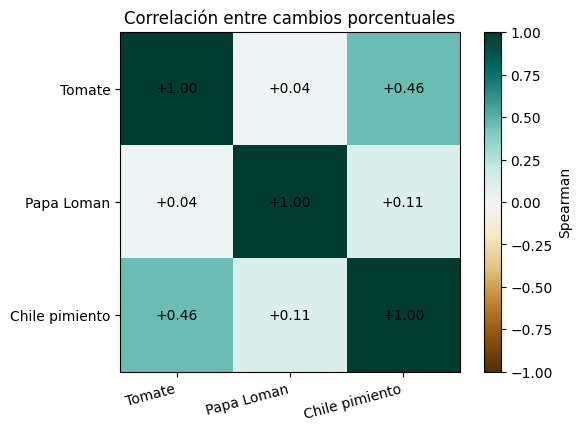

In [6]:
# Revisamos si las variaciones de los tres productos muestran alguna relación.
cambios = series.pivot(index='Fecha', columns='Producto_corto', values='Cambio_pct')[ORDEN].dropna()
correlaciones = cambios.corr(method='spearman').loc[ORDEN, ORDEN]
display(correlaciones.round(3))
tabla(correlaciones.reset_index().rename(columns={'Producto_corto': 'Producto'}), '02_correlaciones.csv')

fig, ax = plt.subplots(figsize=(6, 4.2), layout='constrained')
im = ax.imshow(correlaciones, cmap='BrBG', vmin=-1, vmax=1)
ax.set_xticks(range(3), ORDEN, rotation=15, ha='right')
ax.set_yticks(range(3), ORDEN)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{correlaciones.iloc[i, j]:+.2f}', ha='center', va='center')
fig.colorbar(im, ax=ax, label='Spearman')
ax.set_title('Correlación entre cambios porcentuales')
grafica(fig, '02_correlaciones.png')

## 7. Agrupaciones anuales (K-means)

,k,Silueta,Grupo_minimo
0,2,0.472,22
1,3,0.431,13
2,4,0.398,1
3,5,0.357,1


,Cambio_abs_medio_pct,Desv_cambios_pct,Mediana_cambio_pct,Observaciones
Grupo,,,,
1,15.41,21.31,1.32,59
2,33.50,42.29,1.78,22


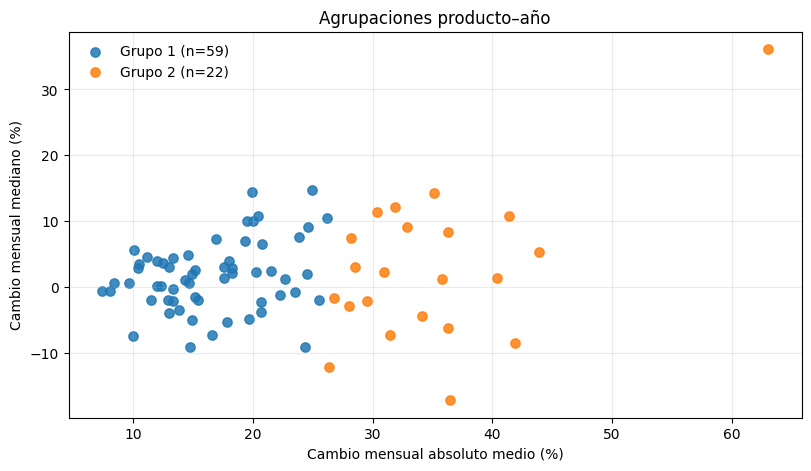

In [7]:
# Resumimos el comportamiento de cada producto en años completos.
base = series.loc[series['Anio'].between(1999, 2025)]
perfiles = (base.groupby(['Producto_corto', 'Anio'])
           .agg(Meses=('Cambio_pct', 'count'),
                Cambio_abs_medio_pct=('Cambio_abs_pct', 'mean'),
                Desv_cambios_pct=('Cambio_pct', 'std'),
                Mediana_cambio_pct=('Cambio_pct', 'median'))
           .reset_index())
assert len(perfiles) == 81 and perfiles['Meses'].eq(12).all()
rasgos = ['Cambio_abs_medio_pct', 'Desv_cambios_pct', 'Mediana_cambio_pct']
# Probamos diferentes agrupaciones y elegimos la que mejor separa los perfiles.
X = StandardScaler().fit_transform(perfiles[rasgos])
seleccion = []
for k in range(2, 6):
    etiquetas = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X)
    seleccion.append((k, silhouette_score(X, etiquetas), np.bincount(etiquetas).min()))
pruebas = pd.DataFrame(seleccion, columns=['k', 'Silueta', 'Grupo_minimo'])
opciones = pruebas.loc[pruebas['Grupo_minimo'] >= 5]
eleccion = (opciones if not opciones.empty else pruebas).sort_values(['Silueta', 'k'], ascending=[False, True]).iloc[0]
k = int(eleccion['k'])
perfiles['Grupo'] = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X) + 1
centros = perfiles.groupby('Grupo')[rasgos].median().round(2)
centros['Observaciones'] = perfiles.groupby('Grupo').size()
display(pruebas.round(3))
display(centros)
tabla(perfiles, '02_grupos_anuales.csv')
tabla(centros.reset_index(), '02_perfiles_grupos.csv')

fig, ax = plt.subplots(figsize=(8, 4.6), layout='constrained')
for grupo, d in perfiles.groupby('Grupo'):
    ax.scatter(d['Cambio_abs_medio_pct'], d['Mediana_cambio_pct'],
               label=f'Grupo {grupo} (n={len(d)})', s=45, alpha=.85)
ax.set_xlabel('Cambio mensual absoluto medio (%)')
ax.set_ylabel('Cambio mensual mediano (%)')
ax.set_title('Agrupaciones producto–año')
ax.legend(frameon=False)
ax.grid(alpha=.25)
grafica(fig, '02_agrupaciones.png')